[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/udayRage/streamPAMI/blob/main/notebooks/frequentPattern/basic/DSTree.ipynb)

# Finding frequent itemsets in transaction streams with DSTree

This tutorial follows PAMI's progression: mine once, evaluate several support
thresholds, then feed batches as a live stream. Pattern supports are counts;
minSup is a fraction, unlike PAMI's optional absolute-count threshold.

[Algorithm documentation and accuracy limits](../../../docs/frequentPattern/basic/DSTree.md)

Locally, install the notebook tools in your virtual environment with
`pip install -e ".[notebooks]"` from the repository root, then select that
environment's Python kernel. Colab already supplies a notebook environment.


## Prerequisites

### Install only if needed

Keep an existing local installation, including an editable checkout. The
conditional installation below runs only if streamPAMI cannot be imported.


In [1]:
try:
    import streamPAMI
except ImportError:
    %pip install -q git+https://github.com/udayRage/streamPAMI


### Download a sample dataset

Use T10I4D100K, also used in the project's evaluation. Python's downloader
works on Windows and Colab. An existing local file is reused.


In [2]:
from pathlib import Path
from urllib.request import urlretrieve

data_path = Path("Transactional_T10I4D100K.csv")
data_url = "https://u-aizu.ac.jp/~udayrage/datasets/transactionalDatabases/Transactional_T10I4D100K.csv"
if not data_path.is_file():
    urlretrieve(data_url, data_path)
print("Dataset:", data_path.name)


Dataset: Transactional_T10I4D100K.csv


### Inspect the input

Each non-blank line is a transaction containing tab-separated item labels.
There is no header or transaction id. Blank file lines are skipped. The
filename is a dataset label; use the actual non-blank transaction count.


In [3]:
from itertools import islice

with data_path.open(encoding="utf-8") as source:
    for line in islice(source, 2):
        print(line.rstrip("\r\n"))
with data_path.open(encoding="utf-8") as source:
    transaction_count = sum(bool(line.strip()) for line in source)
print("Transactions:", transaction_count)


25	52	164	240	274	328	368	448	538	561	630	687	730	775	825	834
39	120	124	205	401	581	704	814	825	834
Transactions: 99935


## Part 1: Mining once

### Step 1: Choose parameters

Choose minSup = 0.006, windowSize = 3 batches and batchSize = 10,000.
The threshold is relative to the transactions in the queried window.
This eager-maintenance variant mines exact results when queried;
its runtime and memory describe this implementation, not the original
authors' deferred-maintenance design.


In [4]:
from streamPAMI.frequentPattern.basic.DSTree import DSTree

batch_size = 10000
min_sup = 0.006
window_size = 3
miner = DSTree(data_path, min_sup, window_size, batch_size)


### Step 2: Mine, print and save

The stored answer covers only the last three batches, including the smaller final batch. Counts are exact.

The saved format is `item1<tab>item2:support`.


In [5]:
miner.mine()
miner.printResults()
output_path = Path("DSTree_patterns.txt")
miner.save(output_path)


Total number of patterns: 787
Total time taken: 6.290132799884304
Total memory in USS: 202436608
Total memory in RSS: 226148352


In [6]:
print("First saved pattern lines:")
with output_path.open(encoding="utf-8") as source:
    for line in islice(source, 5):
        print(line.rstrip("\r\n"))


First saved pattern lines:
998:799
944	998:185
54	998:181
995:426
534	995:207


In [7]:
miner.getPatternsAsDataFrame().head()


,Patterns,Support
0,998,799
1,944\t998,185
2,54\t998,181
3,995,426
4,534\t995,207


## Part 2: Evaluating different minSup values

### Step 1: Choose thresholds and result columns

This illustration rebuilds and replays for each threshold. DSTree also accepts
minSup at query time over the retained window, without replay. Runtime is from mine(), including its final
query. RSS is the captured process memory reading in decimal MB, not a peak.


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
min_sups = [0.006, 0.007, 0.008, 0.009, 0.010]
rows = []


### Step 2: Execute and print the results

Keep windowSize = 3 for every run.


In [9]:
for threshold in min_sups:
    candidate = DSTree(data_path, threshold, window_size, batch_size)
    candidate.mine()
    rows.append({"algorithm": "DSTree", "minSup": threshold,
                 "patterns": len(candidate.getPatterns()),
                 "runtime_s": candidate.getRuntime(),
                 "memory_mb": candidate.getMemoryRSS() / 1000000})
results = pd.DataFrame(rows)
print(results.to_string(index=False))


algorithm  minSup  patterns  runtime_s  memory_mb
   DSTree   0.006       787   7.743855 376.385536
   DSTree   0.007       610   9.181884 375.963648
   DSTree   0.008       510   9.066920 377.171968
   DSTree   0.009       423   9.404946 377.155584
   DSTree   0.010       385   8.885176 387.620864


### Step 3: Visualise the results

These numbers come from sequential runs in one process and are for
illustration. They include process state retained from earlier cells.
Fair measurements are in [benchmarks/](../../../benchmarks/README.md) and
the [README Evaluation section](../../../README.md#evaluation), which
currently compare FP-Stream and DSTree with an exact baseline.


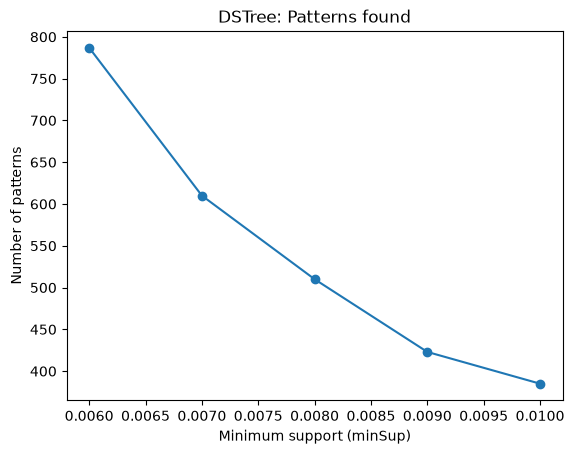

In [10]:
axis = results.plot(x="minSup", y="patterns", marker="o", legend=False,
                    title="DSTree: Patterns found")
axis.set_xlabel("Minimum support (minSup)")
axis.set_ylabel("Number of patterns")
plt.show()


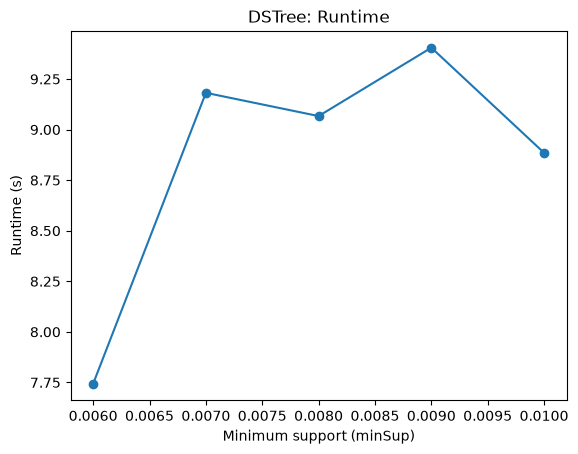

In [11]:
axis = results.plot(x="minSup", y="runtime_s", marker="o", legend=False,
                    title="DSTree: Runtime")
axis.set_xlabel("Minimum support (minSup)")
axis.set_ylabel("Runtime (s)")
plt.show()


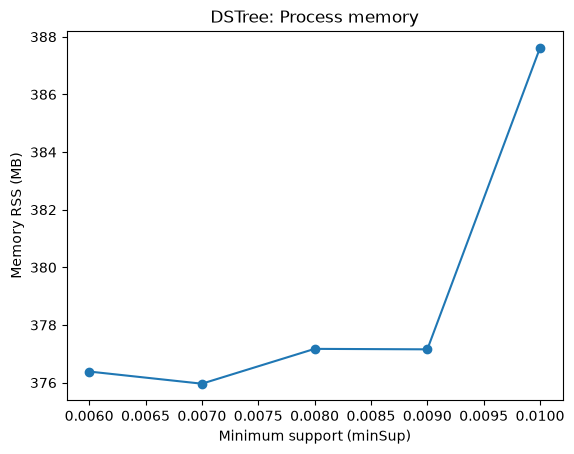

In [12]:
axis = results.plot(x="minSup", y="memory_mb", marker="o", legend=False,
                    title="DSTree: Process memory")
axis.set_xlabel("Minimum support (minSup)")
axis.set_ylabel("Memory RSS (MB)")
plt.show()


## Part 3: Using it as a live stream

Feed the first six full batches. The printed processing time measures only
processBatch(); the following query is outside that timer. queryPatterns()
returns the current answer; getPatterns() remains the last mine() result.


In [13]:
from time import perf_counter

def read_batches(path, size):
    batch = []
    with path.open(encoding="utf-8") as source:
        for line in source:
            line = line.strip()
            if not line:
                continue
            batch.append(line.split("\t"))
            if len(batch) == size:
                yield batch
                batch = []
    if batch:
        yield batch


In [14]:
live = DSTree(None, min_sup, window_size, batch_size)
for batch_number, batch in enumerate(islice(read_batches(data_path, batch_size), 6), start=1):
    started = perf_counter()
    live.processBatch(batch)
    processing_s = perf_counter() - started
    patterns = live.queryPatterns()
    print(f"Batch {batch_number}: patterns={len(patterns)}, processing_s={processing_s:.6f}")
    print("Frames:", live.getTimeFrames())


Batch 1: patterns=814, processing_s=0.118556
Frames: [(0, 1)]


Batch 2: patterns=763, processing_s=0.160788
Frames: [(1, 2), (0, 1)]


Batch 3: patterns=753, processing_s=0.759078
Frames: [(2, 3), (1, 2), (0, 1)]


Batch 4: patterns=744, processing_s=0.949865
Frames: [(3, 4), (2, 3), (1, 2)]


Batch 5: patterns=774, processing_s=0.980858
Frames: [(4, 5), (3, 4), (2, 3)]


Batch 6: patterns=778, processing_s=0.999918
Frames: [(5, 6), (4, 5), (3, 4)]


Compare the newest frame with the whole window. The dictionaries contain counts; the samples below show only their first few sorted entries.


In [15]:
newest = live.queryPatterns(0, 1)
whole = live.queryPatterns()
print("Newest frame patterns:", len(newest))
print("Newest frame sample:", sorted(newest.items())[:5])
print("Whole window patterns:", len(whole))
print("Whole window sample:", sorted(whole.items())[:5])


Newest frame patterns: 872
Newest frame sample: [(('1',), 157), (('10',), 127), (('100',), 167), (('104',), 101), (('105',), 105)]
Whole window patterns: 778
Whole window sample: [(('0',), 181), (('1',), 462), (('10',), 403), (('100',), 548), (('100', '362'), 190)]


The frame list is newest first, with end-exclusive batch boundaries.
After the window fills, its oldest batch leaves on every update. Both
queries are exact over their respective retained batch ranges.


In a real stream, append each broker message's transaction to the current
batch. Call processBatch when the batch is full, query when needed, then
start the next batch. Choose batch and query rates for the application's
latency and memory needs.
